# Tìm hiểu mô hình Decision Tree (DT) và ứng dụng

**Đồ án cơ sở ngành** – Phạm Tuấn Khoa (MSSV 110124095, lớp DA24TTC) – GVHD: ThS. Ngô Thanh Huy

Notebook gồm các phần:
1. Kiểm chứng ví dụ tính tay (tập "Chơi tennis")
2. Khảo sát ba tập dữ liệu công khai: Iris, Wine, Breast Cancer Wisconsin
3. Huấn luyện mô hình với tham số mặc định
4. Trực quan hóa cây và mức độ quan trọng của thuộc tính
5. Thử nghiệm các tham số: criterion, max_depth, min_samples_leaf, ccp_alpha
6. Chọn tham số bằng GridSearchCV và đánh giá trên tập kiểm tra
7. So sánh với mô hình cơ sở (Logistic Regression) bằng kiểm tra chéo 10-fold

Toàn bộ kết quả có thể chạy lại giống nhau nhờ cố định `RANDOM_STATE = 42`. Hình được lưu vào thư mục `figures/`, bảng kết quả lưu vào `results/`.

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import load_iris, load_wine, load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, roc_curve)

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
os.makedirs('figures', exist_ok=True); os.makedirs('results', exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 200, 'font.size': 11})
pd.set_option('display.precision', 4)
print('Python scikit-learn', sklearn.__version__, '| pandas', pd.__version__, '| NumPy', np.__version__)

Python scikit-learn 1.9.1 | pandas 3.0.5 | NumPy 2.5.3


## 1. Kiểm chứng ví dụ tính tay trên tập "Chơi tennis"

In [2]:
tennis = pd.DataFrame({
    'Quang cảnh': ['Nắng','Nắng','U ám','Mưa','Mưa','Mưa','U ám','Nắng','Nắng','Mưa','Nắng','U ám','U ám','Mưa'],
    'Nhiệt độ':   ['Nóng','Nóng','Nóng','Ấm','Mát','Mát','Mát','Ấm','Mát','Ấm','Ấm','Ấm','Nóng','Ấm'],
    'Độ ẩm':      ['Cao','Cao','Cao','Cao','Bình thường','Bình thường','Bình thường','Cao','Bình thường','Bình thường','Bình thường','Cao','Bình thường','Cao'],
    'Gió':        ['Yếu','Mạnh','Yếu','Yếu','Yếu','Mạnh','Mạnh','Yếu','Yếu','Yếu','Mạnh','Mạnh','Yếu','Mạnh'],
    'Chơi tennis':['Không','Không','Có','Có','Có','Không','Có','Không','Có','Có','Có','Có','Có','Không']})

def entropy(y):
    p = y.value_counts(normalize=True)
    return float(-(p * np.log2(p)).sum())

def gini(y):
    p = y.value_counts(normalize=True)
    return float(1 - (p ** 2).sum())

def split_scores(df, attr, target='Chơi tennis'):
    n = len(df); H = entropy(df[target]); rem = gsp = si = 0
    for _, g in df.groupby(attr):
        w = len(g) / n
        rem += w * entropy(g[target]); gsp += w * gini(g[target]); si -= w * np.log2(w)
    ig = H - rem
    return {'Thuộc tính': attr, 'IG': ig, 'SplitInfo': si, 'Gain Ratio': ig / si, 'Gini có trọng số': gsp}

print('H(S) = %.4f   Gini(S) = %.4f' % (entropy(tennis['Chơi tennis']), gini(tennis['Chơi tennis'])))
hand = pd.DataFrame([split_scores(tennis, a) for a in ['Quang cảnh', 'Nhiệt độ', 'Độ ẩm', 'Gió']])
hand.round(3)

H(S) = 0.9403   Gini(S) = 0.4592


,Thuộc tính,IG,SplitInfo,Gain Ratio,Gini có trọng số
0,Quang cảnh,0.247,1.577,0.156,0.343
1,Nhiệt độ,0.029,1.557,0.019,0.440
2,Độ ẩm,0.152,1.000,0.152,0.367
3,Gió,0.048,0.985,0.049,0.429


In [3]:
# Tách tiếp hai nhánh chưa thuần khiết
for v in ['Nắng', 'Mưa']:
    sub = tennis[tennis['Quang cảnh'] == v]
    print('Nhánh', v, '->', {a: round(split_scores(sub, a)['IG'], 3) for a in ['Nhiệt độ', 'Độ ẩm', 'Gió']})

Nhánh Nắng -> {'Nhiệt độ': 0.571, 'Độ ẩm': 0.971, 'Gió': 0.02}
Nhánh Mưa -> {'Nhiệt độ': 0.02, 'Độ ẩm': 0.02, 'Gió': 0.971}


scikit-learn cài đặt CART nên chỉ tạo **cây nhị phân** và chỉ nhận thuộc tính dạng số. Ta mã hóa one-hot rồi huấn luyện với `criterion='entropy'` để đối chiếu với cây tính tay.

|--- Quang cảnh=U ám <= 0.50
|   |--- Độ ẩm=Bình thường <= 0.50
|   |   |--- Quang cảnh=Mưa <= 0.50
|   |   |   |--- class: Không
|   |   |--- Quang cảnh=Mưa >  0.50
|   |   |   |--- Gió=Yếu <= 0.50
|   |   |   |   |--- class: Không
|   |   |   |--- Gió=Yếu >  0.50
|   |   |   |   |--- class: Có
|   |--- Độ ẩm=Bình thường >  0.50
|   |   |--- Gió=Yếu <= 0.50
|   |   |   |--- Quang cảnh=Nắng <= 0.50
|   |   |   |   |--- class: Không
|   |   |   |--- Quang cảnh=Nắng >  0.50
|   |   |   |   |--- class: Có
|   |   |--- Gió=Yếu >  0.50
|   |   |   |--- class: Có
|--- Quang cảnh=U ám >  0.50
|   |--- class: Có

Độ sâu: 4 | Số nút lá: 7 | Độ chính xác trên chính tập dữ liệu: 1.0


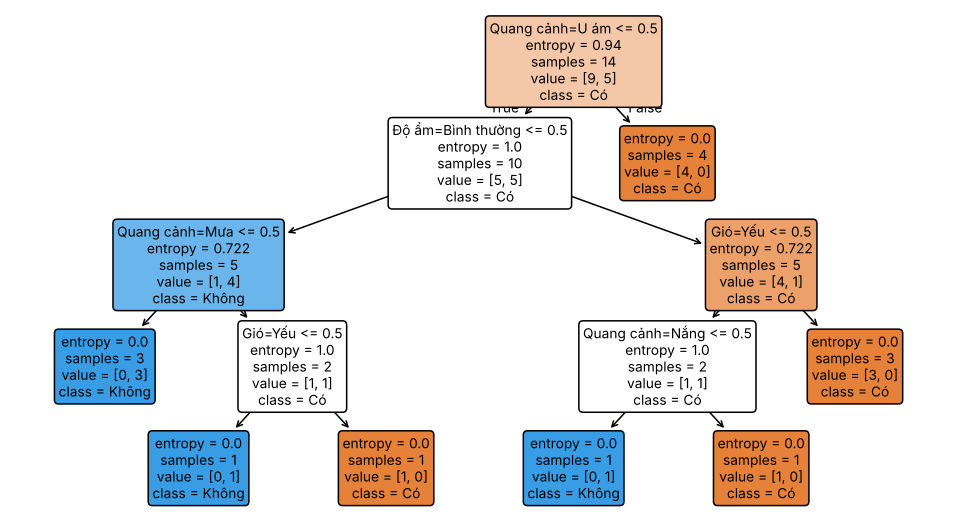

In [4]:
X_t = pd.get_dummies(tennis.drop(columns='Chơi tennis'), prefix_sep='=').astype(int)
y_t = tennis['Chơi tennis']
dt_t = DecisionTreeClassifier(criterion='entropy', random_state=RANDOM_STATE).fit(X_t, y_t)
print(export_text(dt_t, feature_names=list(X_t.columns)))
print('Độ sâu:', dt_t.get_depth(), '| Số nút lá:', dt_t.get_n_leaves(), '| Độ chính xác trên chính tập dữ liệu:', dt_t.score(X_t, y_t))
fig, ax = plt.subplots(figsize=(11, 6))
plot_tree(dt_t, feature_names=list(X_t.columns), class_names=list(dt_t.classes_), filled=True, rounded=True, impurity=True, fontsize=9, ax=ax)
fig.savefig('figures/tennis_sklearn_tree.png', bbox_inches='tight'); plt.show()

## 2. Khảo sát dữ liệu

In [5]:
loaders = {'Iris': load_iris, 'Wine': load_wine, 'Breast Cancer': load_breast_cancer}
DATA = {}
rows = []
for name, f in loaders.items():
    d = f(as_frame=True)
    X, y, names = d.data, d.target, list(d.target_names)
    if name == 'Breast Cancer':
        # Đảo nhãn để lớp dương (1) là 'malignant' (ác tính) – lớp cần phát hiện
        y = (1 - y).rename('target'); names = ['benign', 'malignant']
    DATA[name] = (X, y, names, list(X.columns))
    rows.append({'Tập dữ liệu': name, 'Số mẫu': X.shape[0], 'Số thuộc tính': X.shape[1], 'Số lớp': y.nunique(),
                 'Phân bố lớp': ', '.join(f'{names[k]}: {v}' for k, v in y.value_counts().sort_index().items()),
                 'Giá trị thiếu': int(X.isna().sum().sum())})
overview = pd.DataFrame(rows)
overview.to_csv('results/tong_quan_du_lieu.csv', index=False)
overview

,Tập dữ liệu,Số mẫu,Số thuộc tính,Số lớp,Phân bố lớp,Giá trị thiếu
0,Iris,150,4,3,"setosa: 50, versicolor: 50, virginica: 50",0
1,Wine,178,13,3,"class_0: 59, class_1: 71, class_2: 48",0
2,Breast Cancer,569,30,2,"benign: 357, malignant: 212",0


In [6]:
for name, (X, y, cls, feats) in DATA.items():
    print('=====', name); display(X.describe().T[['mean', 'std', 'min', 'max']].head(6))

===== Iris


,mean,std,min,max
sepal length (cm),5.8433,0.8281,4.3,7.9
sepal width (cm),3.0573,0.4359,2.0,4.4
petal length (cm),3.7580,1.7653,1.0,6.9
petal width (cm),1.1993,0.7622,0.1,2.5


===== Wine


,mean,std,min,max
alcohol,13.0006,0.8118,11.03,14.83
malic_acid,2.3363,1.1171,0.74,5.80
ash,2.3665,0.2743,1.36,3.23
alcalinity_of_ash,19.4949,3.3396,10.60,30.00
magnesium,99.7416,14.2825,70.00,162.00
total_phenols,2.2951,0.6259,0.98,3.88


===== Breast Cancer


,mean,std,min,max
mean radius,14.1273,3.5240,6.9810,28.1100
mean texture,19.2896,4.3010,9.7100,39.2800
mean perimeter,91.9690,24.2990,43.7900,188.5000
mean area,654.8891,351.9141,143.5000,2501.0000
mean smoothness,0.0964,0.0141,0.0526,0.1634
mean compactness,0.1043,0.0528,0.0194,0.3454


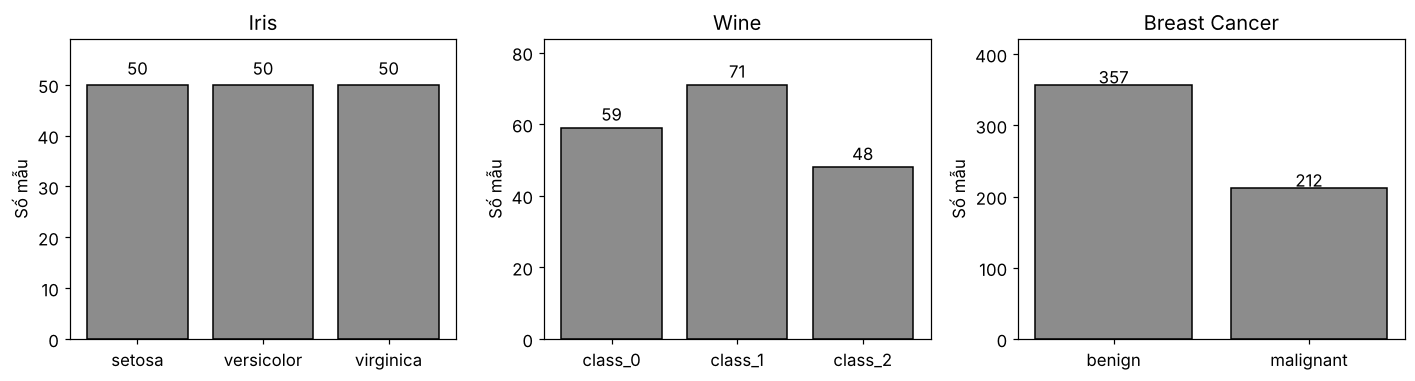

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (name, (X, y, cls, feats)) in zip(axes, DATA.items()):
    cnt = y.value_counts().sort_index()
    ax.bar([cls[i] for i in cnt.index], cnt.values, color='0.55', edgecolor='black')
    for i, v in enumerate(cnt.values): ax.text(i, v + 2, str(v), ha='center')
    ax.set_title(name); ax.set_ylabel('Số mẫu'); ax.set_ylim(0, cnt.max() * 1.18)
fig.tight_layout(); fig.savefig('figures/phan_bo_lop.png', bbox_inches='tight'); plt.show()

## 3. Chia dữ liệu và huấn luyện mô hình mặc định

In [8]:
SPLITS = {}
for name, (X, y, cls, feats) in DATA.items():
    SPLITS[name] = train_test_split(X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE)
    Xtr, Xte, ytr, yte = SPLITS[name]
    print(f'{name}: huấn luyện {len(Xtr)} mẫu, kiểm tra {len(Xte)} mẫu')

def metrics(model, Xte, yte, binary):
    p = model.predict(Xte)
    avg = 'binary' if binary else 'macro'
    return {'Accuracy': accuracy_score(yte, p), 'Precision': precision_score(yte, p, average=avg),
            'Recall': recall_score(yte, p, average=avg), 'F1': f1_score(yte, p, average=avg)}

rows = []
DEFAULT = {}
for name in DATA:
    Xtr, Xte, ytr, yte = SPLITS[name]
    m = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(Xtr, ytr)
    DEFAULT[name] = m
    r = {'Tập dữ liệu': name, 'Độ sâu': m.get_depth(), 'Số nút lá': m.get_n_leaves(),
         'Acc. huấn luyện': m.score(Xtr, ytr)}
    r.update({k if k != 'Accuracy' else 'Acc. kiểm tra': v for k, v in metrics(m, Xte, yte, name == 'Breast Cancer').items()})
    rows.append(r)
default_res = pd.DataFrame(rows)
default_res.to_csv('results/mo_hinh_mac_dinh.csv', index=False)
default_res

Iris: huấn luyện 105 mẫu, kiểm tra 45 mẫu
Wine: huấn luyện 124 mẫu, kiểm tra 54 mẫu
Breast Cancer: huấn luyện 398 mẫu, kiểm tra 171 mẫu


,Tập dữ liệu,Độ sâu,Số nút lá,Acc. huấn luyện,Acc. kiểm tra,Precision,Recall,F1
0,Iris,5,8,1.0,0.9333,0.9444,0.9333,0.9327
1,Wine,4,8,1.0,0.9630,0.9710,0.9593,0.9638
2,Breast Cancer,8,19,1.0,0.9006,0.8852,0.8438,0.8640


## 4. Trực quan hóa cây và mức độ quan trọng của thuộc tính

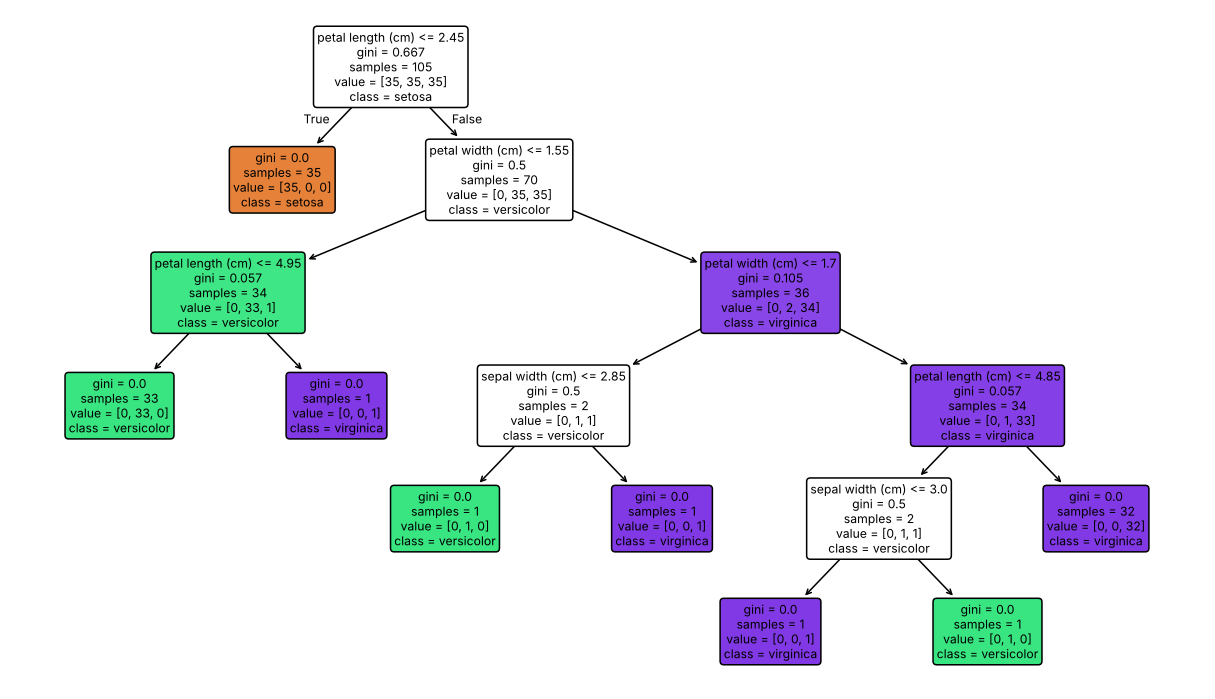

|--- petal length (cm) <= 2.45
|   |--- class: 0
|--- petal length (cm) >  2.45
|   |--- petal width (cm) <= 1.55
|   |   |--- petal length (cm) <= 4.95
|   |   |   |--- class: 1
|   |   |--- petal length (cm) >  4.95
|   |   |   |--- class: 2
|   |--- petal width (cm) >  1.55
|   |   |--- petal width (cm) <= 1.70
|   |   |   |--- sepal width (cm) <= 2.85
|   |   |   |   |--- class: 1
|   |   |   |--- sepal width (cm) >  2.85
|   |   |   |   |--- class: 2
|   |   |--- petal width (cm) >  1.70
|   |   |   |--- petal length (cm) <= 4.85
|   |   |   |   |--- sepal width (cm) <= 3.00
|   |   |   |   |   |--- class: 2
|   |   |   |   |--- sepal width (cm) >  3.00
|   |   |   |   |   |--- class: 1
|   |   |   |--- petal length (cm) >  4.85
|   |   |   |   |--- class: 2



In [9]:
X, y, cls, feats = DATA['Iris']
fig, ax = plt.subplots(figsize=(14, 8))
plot_tree(DEFAULT['Iris'], feature_names=feats, class_names=cls, filled=True, rounded=True, fontsize=8, ax=ax)
fig.savefig('figures/cay_iris_mac_dinh.png', bbox_inches='tight'); plt.show()
print(export_text(DEFAULT['Iris'], feature_names=feats))

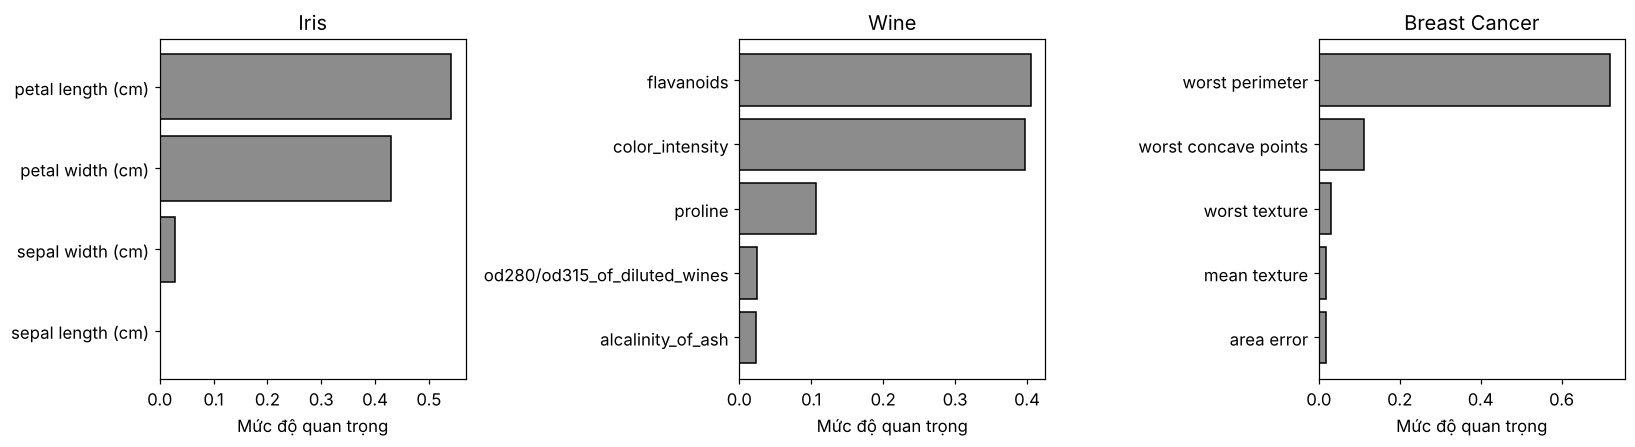

,Iris,Wine,Breast Cancer
0,petal length (cm) (0.541),flavanoids (0.405),worst perimeter (0.72)
1,petal width (cm) (0.43),color_intensity (0.397),worst concave points (0.112)
2,sepal width (cm) (0.029),proline (0.107),worst texture (0.03)
3,sepal length (cm) (0.0),od280/od315_of_diluted_wines (0.024),mean texture (0.019)
4,NaN,alcalinity_of_ash (0.024),area error (0.017)


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
IMP = {}
for ax, name in zip(axes, DATA):
    feats = DATA[name][3]
    imp = pd.Series(DEFAULT[name].feature_importances_, index=feats).sort_values(ascending=False)
    IMP[name] = imp
    top = imp.head(5)[::-1]
    ax.barh(top.index, top.values, color='0.55', edgecolor='black'); ax.set_title(name); ax.set_xlabel('Mức độ quan trọng')
fig.tight_layout(); fig.savefig('figures/muc_do_quan_trong.png', bbox_inches='tight'); plt.show()
pd.DataFrame({n: IMP[n].head(5).round(3).reset_index().apply(lambda r: f'{r.iloc[0]} ({r.iloc[1]})', axis=1) for n in IMP})

## 5. Thử nghiệm các tham số
### 5.1. Tiêu chí tách: gini và entropy

In [11]:
cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name in DATA:
    X, y = DATA[name][0], DATA[name][1]
    Xtr, Xte, ytr, yte = SPLITS[name]
    for crit in ['gini', 'entropy']:
        m = DecisionTreeClassifier(criterion=crit, random_state=RANDOM_STATE).fit(Xtr, ytr)
        cv = cross_validate(DecisionTreeClassifier(criterion=crit, random_state=RANDOM_STATE), X, y, cv=cv10)
        rows.append({'Tập dữ liệu': name, 'criterion': crit, 'Độ sâu': m.get_depth(), 'Số nút lá': m.get_n_leaves(),
                     'Acc. kiểm tra': m.score(Xte, yte), 'Acc. 10-fold (TB)': cv['test_score'].mean(), 'Độ lệch chuẩn': cv['test_score'].std()})
crit_res = pd.DataFrame(rows); crit_res.to_csv('results/tieu_chi_tach.csv', index=False); crit_res

,Tập dữ liệu,criterion,Độ sâu,Số nút lá,Acc. kiểm tra,Acc. 10-fold (TB),Độ lệch chuẩn
0,Iris,gini,5,8,0.9333,0.9333,0.0516
1,Iris,entropy,6,8,0.8889,0.9333,0.0516
2,Wine,gini,4,8,0.9630,0.8997,0.0776
3,Wine,entropy,3,6,0.9074,0.9163,0.0869
4,Breast Cancer,gini,8,19,0.9006,0.9262,0.0233
5,Breast Cancer,entropy,8,16,0.9415,0.9350,0.0260


### 5.2. Độ sâu tối đa (max_depth) và hiện tượng quá khớp

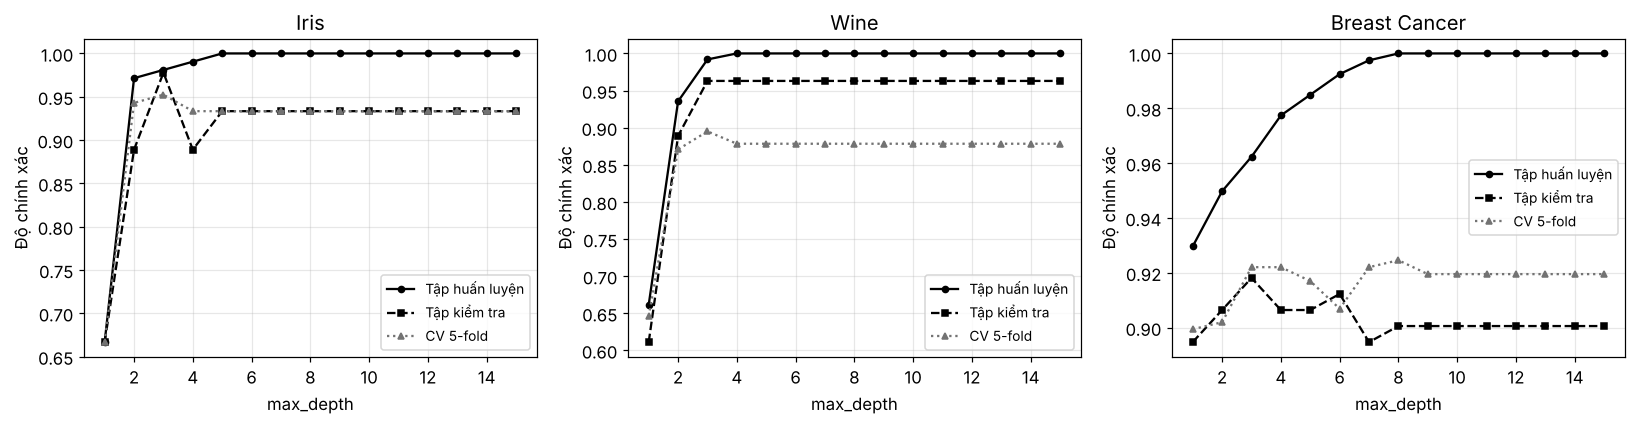

Iris


,max_depth,Huấn luyện,Kiểm tra,CV 5-fold (tập huấn luyện)
0,1,0.6667,0.6667,0.6667
1,2,0.9714,0.8889,0.9429
2,3,0.9810,0.9778,0.9524
3,4,0.9905,0.8889,0.9333
4,5,1.0000,0.9333,0.9333
5,6,1.0000,0.9333,0.9333
6,7,1.0000,0.9333,0.9333
7,8,1.0000,0.9333,0.9333


Wine


,max_depth,Huấn luyện,Kiểm tra,CV 5-fold (tập huấn luyện)
0,1,0.6613,0.6111,0.6457
1,2,0.9355,0.8889,0.8707
2,3,0.9919,0.9630,0.8950
3,4,1.0000,0.9630,0.8783
4,5,1.0000,0.9630,0.8783
5,6,1.0000,0.9630,0.8783
6,7,1.0000,0.9630,0.8783
7,8,1.0000,0.9630,0.8783


Breast Cancer


,max_depth,Huấn luyện,Kiểm tra,CV 5-fold (tập huấn luyện)
0,1,0.9296,0.8947,0.8994
1,2,0.9497,0.9064,0.9020
2,3,0.9623,0.9181,0.9221
3,4,0.9774,0.9064,0.9221
4,5,0.9849,0.9064,0.9170
5,6,0.9925,0.9123,0.9069
6,7,0.9975,0.8947,0.9221
7,8,1.0000,0.9006,0.9246


In [12]:
depths = range(1, 16)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
DEPTH = {}
for ax, name in zip(axes, DATA):
    X, y = DATA[name][0], DATA[name][1]
    Xtr, Xte, ytr, yte = SPLITS[name]
    tr, te, cvm = [], [], []
    for d in depths:
        m = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE).fit(Xtr, ytr)
        tr.append(m.score(Xtr, ytr)); te.append(m.score(Xte, yte))
        cvm.append(cross_validate(DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE), Xtr, ytr, cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE))['test_score'].mean())
    DEPTH[name] = pd.DataFrame({'max_depth': list(depths), 'Huấn luyện': tr, 'Kiểm tra': te, 'CV 5-fold (tập huấn luyện)': cvm})
    ax.plot(depths, tr, 'k-o', ms=4, label='Tập huấn luyện'); ax.plot(depths, te, 'k--s', ms=4, label='Tập kiểm tra')
    ax.plot(depths, cvm, ':^', color='0.45', ms=4, label='CV 5-fold')
    ax.set_title(name); ax.set_xlabel('max_depth'); ax.set_ylabel('Độ chính xác'); ax.grid(alpha=.3); ax.legend(fontsize=9)
fig.tight_layout(); fig.savefig('figures/do_sau_qua_khop.png', bbox_inches='tight'); plt.show()
pd.concat({k: v.set_index('max_depth') for k, v in DEPTH.items()}, axis=1).to_csv('results/max_depth.csv')
for k, v in DEPTH.items(): print(k); display(v.round(4).head(8))

### 5.3. Số mẫu tối thiểu ở nút lá (min_samples_leaf)

In [13]:
rows = []
for name in DATA:
    Xtr, Xte, ytr, yte = SPLITS[name]
    for leaf in [1, 2, 5, 10, 20]:
        m = DecisionTreeClassifier(min_samples_leaf=leaf, random_state=RANDOM_STATE).fit(Xtr, ytr)
        rows.append({'Tập dữ liệu': name, 'min_samples_leaf': leaf, 'Độ sâu': m.get_depth(), 'Số nút lá': m.get_n_leaves(),
                     'Acc. huấn luyện': m.score(Xtr, ytr), 'Acc. kiểm tra': m.score(Xte, yte)})
leaf_res = pd.DataFrame(rows); leaf_res.to_csv('results/min_samples_leaf.csv', index=False); leaf_res

,Tập dữ liệu,min_samples_leaf,Độ sâu,Số nút lá,Acc. huấn luyện,Acc. kiểm tra
0,Iris,1,5,8,1.0000,0.9333
1,Iris,2,4,6,0.9714,0.8889
2,Iris,5,3,5,0.9714,0.8889
3,Iris,10,3,5,0.9714,0.8889
4,Iris,20,2,3,0.9714,0.8889
5,Wine,1,4,8,1.0000,0.9630
6,Wine,2,4,8,0.9839,1.0000
7,Wine,5,3,6,0.9677,0.9630
8,Wine,10,3,6,0.9435,0.9074
9,Wine,20,3,5,0.9274,0.8889


### 5.4. Cắt tỉa theo độ phức tạp chi phí (ccp_alpha) trên Breast Cancer

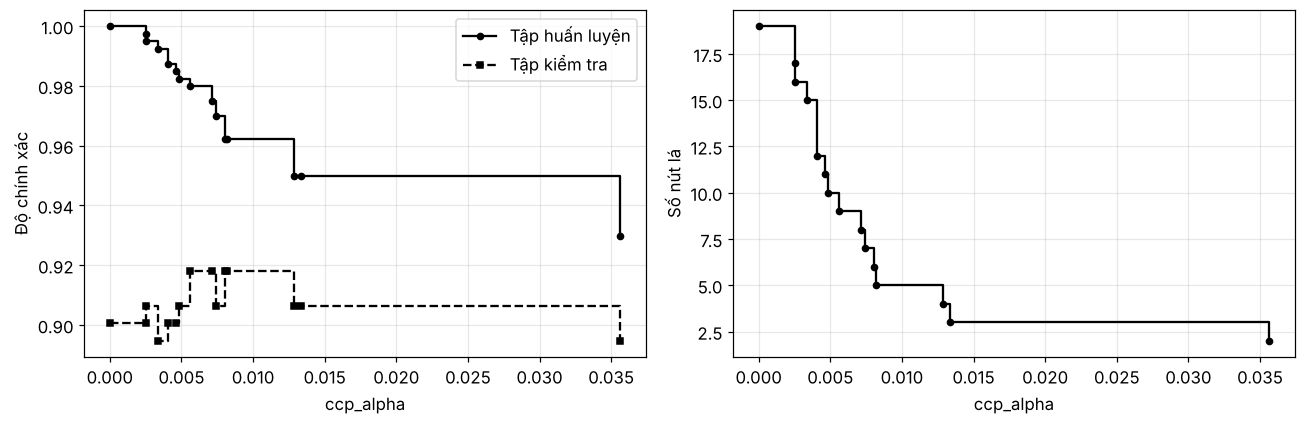

,ccp_alpha,Số nút lá,Huấn luyện,Kiểm tra
0,0.0000,19,1.0000,0.9006
1,0.0025,17,0.9975,0.9006
2,0.0025,16,0.9950,0.9064
3,0.0034,15,0.9925,0.8947
4,0.0041,12,0.9874,0.9006
5,0.0046,11,0.9849,0.9006
6,0.0048,10,0.9824,0.9064
7,0.0056,9,0.9799,0.9181
8,0.0071,8,0.9749,0.9181
9,0.0074,7,0.9698,0.9064


In [14]:
Xtr, Xte, ytr, yte = SPLITS['Breast Cancer']
path = DecisionTreeClassifier(random_state=RANDOM_STATE).cost_complexity_pruning_path(Xtr, ytr)
alphas = path.ccp_alphas[:-1]          # bỏ alpha cuối (cây chỉ còn nút gốc)
tr, te, leaves = [], [], []
for a in alphas:
    m = DecisionTreeClassifier(ccp_alpha=a, random_state=RANDOM_STATE).fit(Xtr, ytr)
    tr.append(m.score(Xtr, ytr)); te.append(m.score(Xte, yte)); leaves.append(m.get_n_leaves())
ccp = pd.DataFrame({'ccp_alpha': alphas, 'Số nút lá': leaves, 'Huấn luyện': tr, 'Kiểm tra': te})
ccp.to_csv('results/ccp_alpha_breast_cancer.csv', index=False)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(alphas, tr, 'k-o', ms=4, drawstyle='steps-post', label='Tập huấn luyện')
ax[0].plot(alphas, te, 'k--s', ms=4, drawstyle='steps-post', label='Tập kiểm tra')
ax[0].set_xlabel('ccp_alpha'); ax[0].set_ylabel('Độ chính xác'); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(alphas, leaves, 'k-o', ms=4, drawstyle='steps-post'); ax[1].set_xlabel('ccp_alpha'); ax[1].set_ylabel('Số nút lá'); ax[1].grid(alpha=.3)
fig.tight_layout(); fig.savefig('figures/ccp_alpha.png', bbox_inches='tight'); plt.show()
ccp.round(4)

## 6. Chọn tham số bằng GridSearchCV và đánh giá trên tập kiểm tra

In [15]:
grid = {'criterion': ['gini', 'entropy'], 'max_depth': [2, 3, 4, 5, 6, 8, None],
        'min_samples_leaf': [1, 2, 5, 10], 'ccp_alpha': [0.0, 0.005, 0.01, 0.02]}
BEST, rows = {}, []
for name in DATA:
    Xtr, Xte, ytr, yte = SPLITS[name]
    gs = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), grid, scoring='f1_macro',
                      cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), n_jobs=-1).fit(Xtr, ytr)
    m = gs.best_estimator_; BEST[name] = m
    r = {'Tập dữ liệu': name, 'Tham số tốt nhất': gs.best_params_, 'F1 CV (huấn luyện)': gs.best_score_,
         'Độ sâu': m.get_depth(), 'Số nút lá': m.get_n_leaves(), 'Acc. huấn luyện': m.score(Xtr, ytr)}
    r.update({k if k != 'Accuracy' else 'Acc. kiểm tra': v for k, v in metrics(m, Xte, yte, name == 'Breast Cancer').items()})
    rows.append(r)
best_res = pd.DataFrame(rows); best_res.to_csv('results/mo_hinh_toi_uu.csv', index=False); best_res

,Tập dữ liệu,Tham số tốt nhất,F1 CV (huấn luyện),Độ sâu,Số nút lá,Acc. huấn luyện,Acc. kiểm tra,Precision,Recall,F1
0,Iris,"{'ccp_alpha': 0.0, 'criterion': 'gini', 'max_d...",0.9519,3,5,0.9810,0.9778,0.9792,0.9778,0.9778
1,Wine,"{'ccp_alpha': 0.02, 'criterion': 'gini', 'max_...",0.9010,3,4,0.9677,0.9630,0.9710,0.9630,0.9652
2,Breast Cancer,"{'ccp_alpha': 0.0, 'criterion': 'entropy', 'ma...",0.9295,3,7,0.9648,0.9532,1.0000,0.8750,0.9333


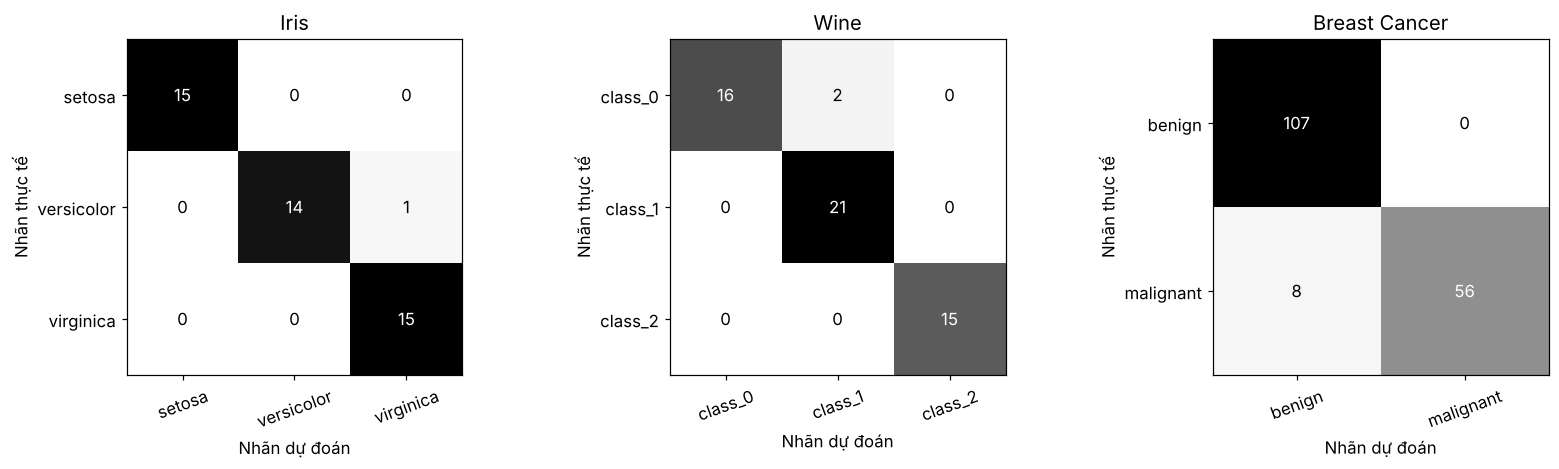

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, name in zip(axes, DATA):
    Xtr, Xte, ytr, yte = SPLITS[name]; cls = DATA[name][2]
    ConfusionMatrixDisplay.from_estimator(BEST[name], Xte, yte, display_labels=cls, cmap='Greys', colorbar=False, ax=ax)
    ax.set_title(name); ax.set_xlabel('Nhãn dự đoán'); ax.set_ylabel('Nhãn thực tế')
    ax.tick_params(axis='x', labelrotation=20)
fig.tight_layout(); fig.savefig('figures/ma_tran_nham_lan.png', bbox_inches='tight'); plt.show()

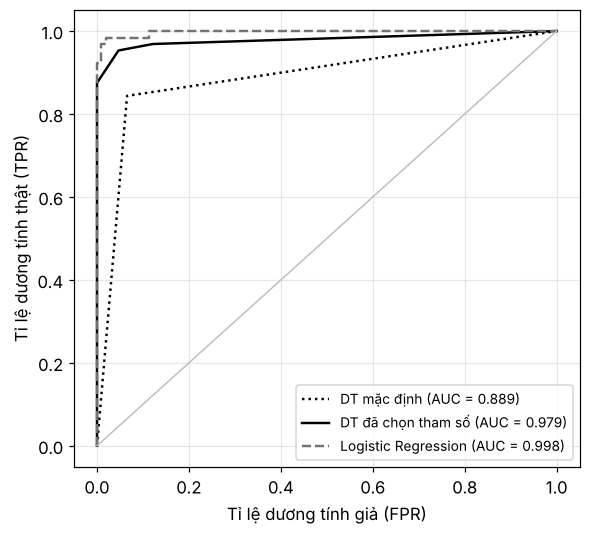

{'DT mặc định': 0.8891647196261683,
 'DT đã chọn tham số': 0.9793370327102804,
 'Logistic Regression': 0.997517523364486}

In [17]:
# ROC – AUC cho bài toán nhị phân Breast Cancer (lớp dương = malignant)
Xtr, Xte, ytr, yte = SPLITS['Breast Cancer']
lr_bc = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)).fit(Xtr, ytr)
fig, ax = plt.subplots(figsize=(5.5, 5))
AUC = {}
for lab, m, st in [('DT mặc định', DEFAULT['Breast Cancer'], ':'), ('DT đã chọn tham số', BEST['Breast Cancer'], '-'), ('Logistic Regression', lr_bc, '--')]:
    prob = m.predict_proba(Xte)[:, 1]; AUC[lab] = roc_auc_score(yte, prob)
    fpr, tpr, _ = roc_curve(yte, prob)
    ax.plot(fpr, tpr, linestyle=st, color='k' if 'DT' in lab else '0.45', lw=1.6, label=f'{lab} (AUC = {AUC[lab]:.3f})')
ax.plot([0, 1], [0, 1], color='0.75', lw=1); ax.legend(loc='lower right', fontsize=9); ax.grid(alpha=.3); ax.set_xlabel('Tỉ lệ dương tính giả (FPR)'); ax.set_ylabel('Tỉ lệ dương tính thật (TPR)')
fig.tight_layout(); fig.savefig('figures/roc_breast_cancer.png', bbox_inches='tight'); plt.show()
AUC

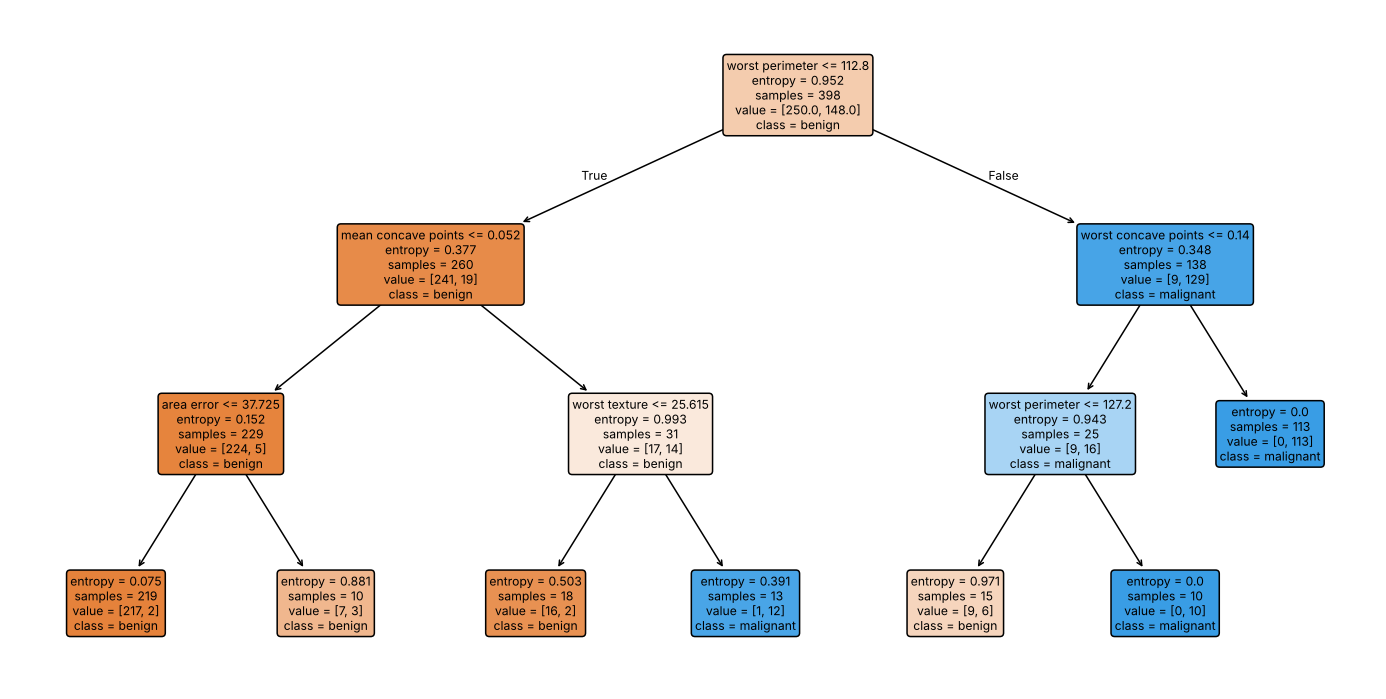

|--- worst perimeter <= 112.80
|   |--- mean concave points <= 0.05
|   |   |--- area error <= 37.73
|   |   |   |--- class: 0
|   |   |--- area error >  37.73
|   |   |   |--- class: 0
|   |--- mean concave points >  0.05
|   |   |--- worst texture <= 25.61
|   |   |   |--- class: 0
|   |   |--- worst texture >  25.61
|   |   |   |--- class: 1
|--- worst perimeter >  112.80
|   |--- worst concave points <= 0.14
|   |   |--- worst perimeter <= 127.20
|   |   |   |--- class: 0
|   |   |--- worst perimeter >  127.20
|   |   |   |--- class: 1
|   |--- worst concave points >  0.14
|   |   |--- class: 1



In [18]:
X, y, cls, feats = DATA['Breast Cancer']
fig, ax = plt.subplots(figsize=(16, 8))
plot_tree(BEST['Breast Cancer'], feature_names=feats, class_names=cls, filled=True, rounded=True, fontsize=8, ax=ax)
fig.savefig('figures/cay_breast_cancer_toi_uu.png', bbox_inches='tight'); plt.show()
print(export_text(BEST['Breast Cancer'], feature_names=feats))

## 7. So sánh với mô hình cơ sở bằng kiểm tra chéo 10-fold

In [19]:
models = {'DT mặc định': lambda n: DecisionTreeClassifier(random_state=RANDOM_STATE),
          'DT đã chọn tham số': lambda n: DecisionTreeClassifier(random_state=RANDOM_STATE, **{k: v for k, v in BEST[n].get_params().items() if k in grid}),
          'Logistic Regression': lambda n: make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))}
rows = []
for name in DATA:
    X, y = DATA[name][0], DATA[name][1]
    for lab, mk in models.items():
        cv = cross_validate(mk(name), X, y, cv=cv10, scoring=['accuracy', 'f1_macro'])
        rows.append({'Tập dữ liệu': name, 'Mô hình': lab,
                     'Accuracy TB': cv['test_accuracy'].mean(), 'Accuracy ĐLC': cv['test_accuracy'].std(),
                     'F1-macro TB': cv['test_f1_macro'].mean(), 'F1-macro ĐLC': cv['test_f1_macro'].std()})
cmp_res = pd.DataFrame(rows); cmp_res.to_csv('results/so_sanh_10fold.csv', index=False); cmp_res

,Tập dữ liệu,Mô hình,Accuracy TB,Accuracy ĐLC,F1-macro TB,F1-macro ĐLC
0,Iris,DT mặc định,0.9333,0.0516,0.9320,0.0531
1,Iris,DT đã chọn tham số,0.9400,0.0554,0.9387,0.0569
2,Iris,Logistic Regression,0.9533,0.0521,0.9526,0.0531
3,Wine,DT mặc định,0.8997,0.0776,0.9018,0.0767
4,Wine,DT đã chọn tham số,0.8944,0.0877,0.8961,0.0863
5,Wine,Logistic Regression,0.9833,0.0255,0.9829,0.0262
6,Breast Cancer,DT mặc định,0.9262,0.0233,0.9208,0.0248
7,Breast Cancer,DT đã chọn tham số,0.9086,0.0348,0.9002,0.0428
8,Breast Cancer,Logistic Regression,0.9754,0.0195,0.9733,0.0215


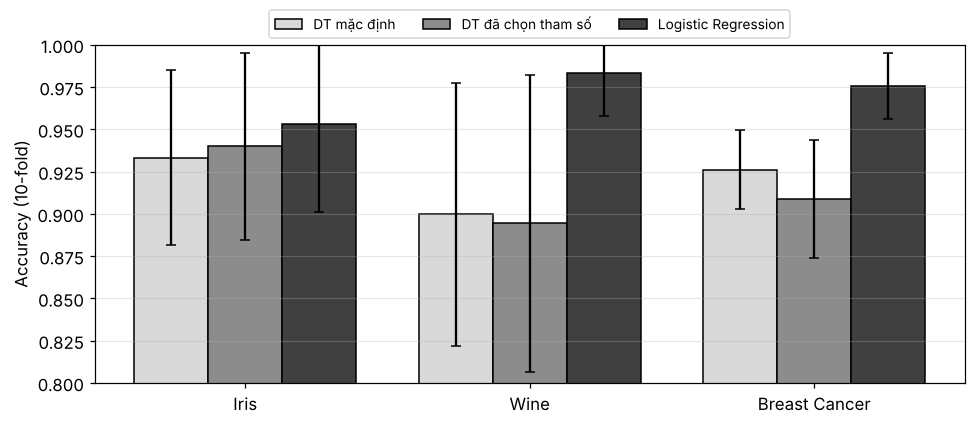

In [20]:
piv = cmp_res.pivot(index='Tập dữ liệu', columns='Mô hình', values='Accuracy TB').loc[list(DATA)]
err = cmp_res.pivot(index='Tập dữ liệu', columns='Mô hình', values='Accuracy ĐLC').loc[list(DATA)]
fig, ax = plt.subplots(figsize=(9, 4))
w = 0.26; xs = np.arange(len(piv))
for k, (col, c) in enumerate(zip(['DT mặc định', 'DT đã chọn tham số', 'Logistic Regression'], ['0.85', '0.55', '0.25'])):
    ax.bar(xs + (k - 1) * w, piv[col], w, yerr=err[col], capsize=3, color=c, edgecolor='black', label=col)
ax.set_xticks(xs); ax.set_xticklabels(piv.index); ax.set_ylim(0.8, 1.0); ax.set_ylabel('Accuracy (10-fold)')
ax.legend(ncol=3, fontsize=9, loc='lower center', bbox_to_anchor=(0.5, 1.0)); ax.grid(axis='y', alpha=.3)
fig.tight_layout(); fig.savefig('figures/so_sanh_mo_hinh.png', bbox_inches='tight'); plt.show()